In [223]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [372]:
#looking at abundence data: replace -9999 with NA and -8888 with 0 values !!surface oxygen data added to the nodule abundence file!!
abundence = pd.read_csv("2026-604-FA_NoduleAbundance.csv", na_values = "-9999")
abundence.replace([-8888], 0, inplace=True)
abundence.head()

,Cruise_ID,Core_ID,Node,Surf_oxygen_conc uM/L,Date_On_Bottom,Time_On_Bottom,Surface_Abundance,Whole_Box_Abundance,Latitude_USBL,Longitude_USBL,Latitude_Ship,Longitude_Ship,Water_Depth
0,2026-604-FA,BX01,5K,NaN,4/13/2026,22:51,NaN,NaN,NaN,NaN,-13.83505,-166.91699,5440
1,2026-604-FA,BX02,7L,NaN,4/14/2026,9:44,NaN,NaN,NaN,NaN,-13.46979,-166.54270,5643
2,2026-604-FA,BX03,7L,303.711609,4/14/2026,19:00,15.1,16.4,NaN,NaN,-13.46984,-166.54275,5644
3,2026-604-FA,BX04,8K,255.519608,4/15/2026,4:40,0.0,0.0,NaN,NaN,-13.64489,-166.35907,5426
4,2026-604-FA,BX05,8J,265.351105,4/15/2026,14:41,10.9,10.9,NaN,NaN,-14.04159,-166.36119,5494


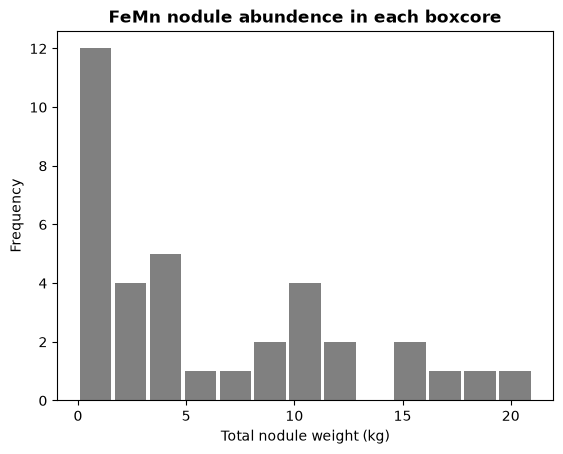

In [373]:
#looking at spread of abundence data
fig, ax = plt.subplots()
ax.hist(abundence['Whole_Box_Abundance'], bins = 13,rwidth=0.90,color="grey")
ax.set_xlabel("Total nodule weight (kg)")
ax.set_ylabel("Frequency")
ax.set_title("FeMn nodule abundence in each boxcore", weight = "bold")
fig.savefig("Nod abundence historgram.png", dpi = 300, bbox_inches = 'tight')

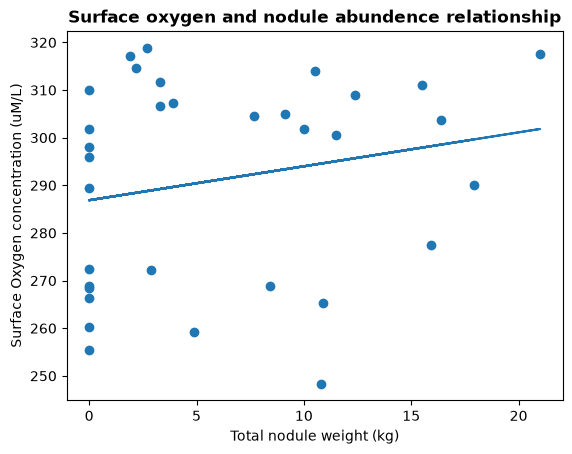

In [374]:
#compare surface oxygen to nodule abundence (cleaned abundence removes rows if NA from abundance or surf oxy)  
fig, ax = plt.subplots()
clean_abundence = abundence[['Whole_Box_Abundance', 'Surf_oxygen_conc uM/L']].dropna()
ax.scatter(clean_abundence['Whole_Box_Abundance'], clean_abundence['Surf_oxygen_conc uM/L'])
ax.set_xlabel('Total nodule weight (kg)')
ax.set_ylabel("Surface Oxygen concentration (uM/L)")
ax.set_title("Surface oxygen and nodule abundence relationship", weight = "bold")

lines = stats.linregress(clean_abundence['Whole_Box_Abundance'], clean_abundence['Surf_oxygen_conc uM/L'])
ax.plot(clean_abundence['Whole_Box_Abundance'], lines.slope*clean_abundence['Whole_Box_Abundance']+ lines.intercept)

clean_abundence['Whole_Box_Abundance'].corr( clean_abundence['Surf_oxygen_conc uM/L'])
fig.savefig("Surf oxy and nodule abundence relationship.png", dpi = 300, bbox_inches = 'tight')

np.float64(0.200609620521498)

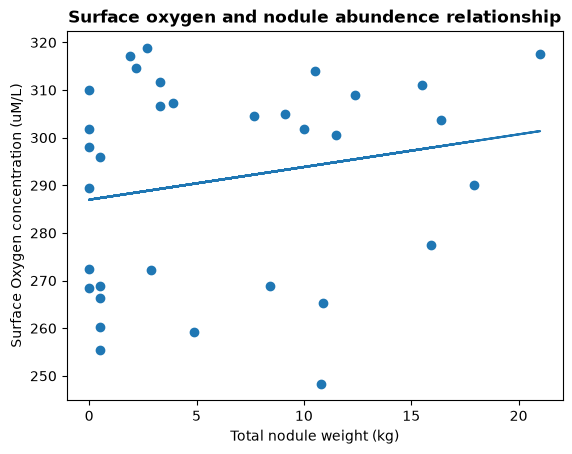

In [375]:
#compare surface oxygen to nodule abundence with below detection limit values saved as 0.5: new file _NoduleAbundence_NO_bDL
fig, ax = plt.subplots()
abundence_DL = pd.read_csv("2026-604-FA_NoduleAbundance_NO_bDL.csv", na_values = "-9999")

clean_abundence_DL = abundence_DL[['Whole_Box_Abundance', 'Surf_oxygen_conc uM/L']].dropna()
ax.scatter(clean_abundence_DL['Whole_Box_Abundance'], clean_abundence_DL['Surf_oxygen_conc uM/L'])
ax.set_xlabel('Total nodule weight (kg)')
ax.set_ylabel("Surface Oxygen concentration (uM/L)")
ax.set_title("Surface oxygen and nodule abundence relationship", weight = "bold")

lines = stats.linregress(clean_abundence_DL['Whole_Box_Abundance'], clean_abundence_DL['Surf_oxygen_conc uM/L'])
ax.plot(clean_abundence_DL['Whole_Box_Abundance'], lines.slope*clean_abundence_DL['Whole_Box_Abundance']+ lines.intercept)

clean_abundence_DL['Whole_Box_Abundance'].corr( clean_abundence_DL['Surf_oxygen_conc uM/L'])
#fig.savefig("Surf oxy and nodule abundence relationship.png", dpi = 300, bbox_inches = 'tight')

In [376]:
#Looking at full oxygen data set: using only good data quality code=1
oxy = pd.read_csv("2026_604_FA_oxygen.csv")
oxy_cleaned = oxy[oxy['Quality_code'] <= 1]
oxy_cleaned.head()

,Core_ID,Latitude,Longitude,Boxcore_Depth_m,Time_since_program_start_s,Oxygen_uM_per_L,Electrode_type,Depth_cm,Quality_code
0,2026_604_FA_BX03_PC01,-13.4698,-166.5428,5644,525.554,303.711609,OX-100,1,1
1,2026_604_FA_BX03_PC01,-13.4698,-166.5428,5644,592.882,278.437622,OX-100,2,1
2,2026_604_FA_BX03_PC01,-13.4698,-166.5428,5644,647.137,259.643555,OX-100,3,1
3,2026_604_FA_BX03_PC01,-13.4698,-166.5428,5644,719.477,255.039291,OX-100,4,1
4,2026_604_FA_BX03_PC01,-13.4698,-166.5428,5644,768.729,234.702332,OX-100,5,1


In [377]:
#Make new surface data: using only good data quality code = 1 again
oxy_surf =oxy[oxy['Depth_cm'] == 1].copy()
oxy_surf = oxy_surf[oxy_surf['Quality_code'] <= 1]
oxy_surf.head()

,Core_ID,Latitude,Longitude,Boxcore_Depth_m,Time_since_program_start_s,Oxygen_uM_per_L,Electrode_type,Depth_cm,Quality_code
0,2026_604_FA_BX03_PC01,-13.4698,-166.5428,5644,525.554,303.711609,OX-100,1,1
26,2026_604_FA_BX05_PC01,-14.0416,-166.3612,5494,454.256,265.351105,OX-100,1,1
42,2026_604_FA_BX06_PC01,-14.3933,-166.3641,5668,131.575,248.355499,OX-200,1,1
48,2026_604_FA_BX07_PC01,-14.7993,-166.3658,5563,543.674,301.778168,OX-200,1,1
83,2026_604_FA_BX09_PC01,-15.4678,-166.3700,5476,467.386,307.197998,OX-200,1,1


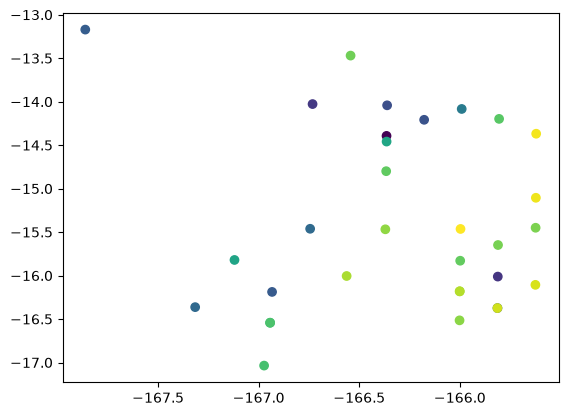

In [387]:
#Oxygen surf conc by location?
fig, ax = plt.subplots()
ax.scatter(oxy_surf['Longitude'],oxy_surf['Latitude'], c=oxy_surf['Oxygen_uM_per_L'])

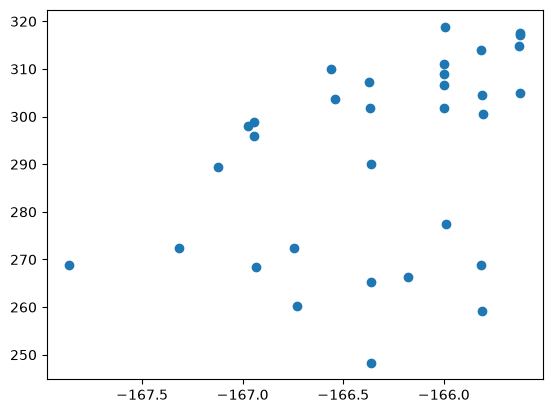

In [388]:
fig, ax = plt.subplots()
ax.scatter(oxy_surf['Longitude'], oxy_surf['Oxygen_uM_per_L'])

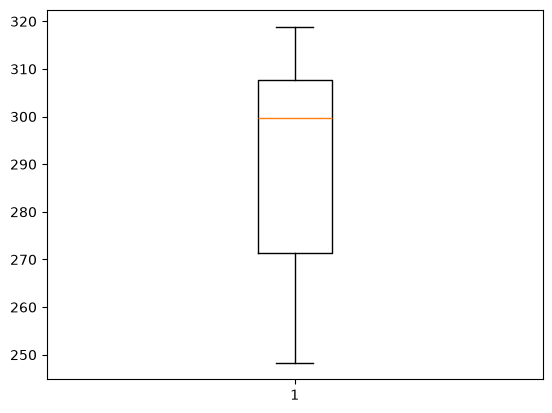

In [7]:
#Spread of surface oxygen data:
plt.boxplot(oxy_surf['Oxygen_uM_per_L'])
plt.show()

In [19]:
#Plot highes and lowest oxygen profiles 
lowest_bx = oxy_surf.loc[oxy_surf['Oxygen_uM_per_L'].idxmin(), 'Core_ID']
highest_bx = oxy_surf.loc[oxy_surf['Oxygen_uM_per_L'].idxmax(), 'Core_ID']
lowest_bx

'2026_604_FA_BX06_PC01'

In [20]:
BX29 = oxy_cleaned[oxy_cleaned['Core_ID'].str.contains('2026_604_FA_BX29_PC01')].copy()
BX06 = oxy_cleaned[oxy_cleaned['Core_ID'].str.contains('2026_604_FA_BX06_PC01')].copy()

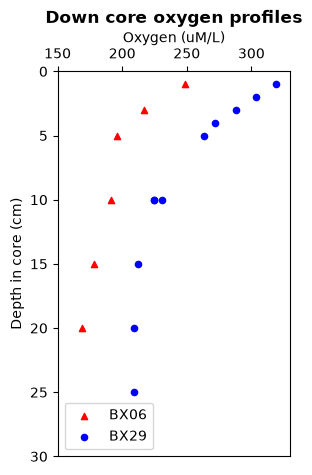

In [51]:
xBX06 = BX06.Oxygen_uM_per_L
yBX06 = BX06.Depth_cm
xBX29 = BX29.Oxygen_uM_per_L
yBX29 = BX29.Depth_cm

fig, ax = plt.subplots(figsize = (3,5))

BX06.plot.scatter(x ='Oxygen_uM_per_L', y='Depth_cm', ax=ax, marker = '^', label = 'BX06', color = 'red')
BX29.plot.scatter(x ='Oxygen_uM_per_L', y='Depth_cm', ax=ax, label = 'BX29', color = 'blue')

ax.set_ylabel('Depth in core (cm)')
ax.set_xlabel('Oxygen (uM/L)')
ax.xaxis.set_label_position('top')
ax.set_ylim(30,0)
ax.set_xlim(150,330)
ax.xaxis.tick_top()
ax.set_title("Down core oxygen profiles", weight = 'bold')
#plt.show()
fig.savefig("Low_high_oxy.png", dpi = 300, bbox_inches = 'tight')

C:\Users\isabe\AppData\Local\Temp\ipykernel_41936\2374477276.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  geochem['Fe_Mn_ratio'] = geochem['Fe'] / geochem['Mn']


Text(0.5, 1.0, 'All mineral samples')

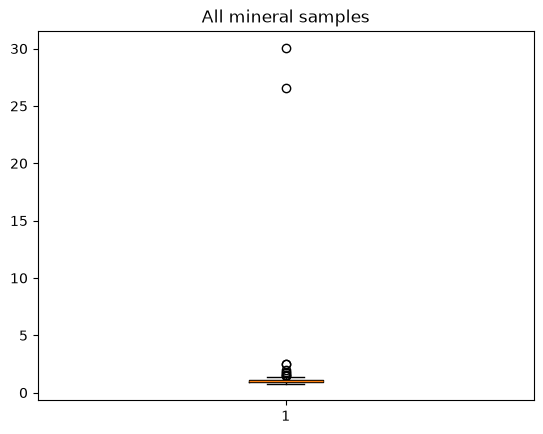

In [238]:
#Look at geochem data: create Fe/Mn ratio column and look at spread : CRMs removed here
geochem = pd.read_csv("2026-604-FA_NoduleGeochemistry.csv", na_values = "-9999")
geochem.head()
geochem['Fe_Mn_ratio'] = geochem['Fe'] / geochem['Mn']
geochem = geochem[geochem['Sample_Type'] != 'certified reference material']

plt.boxplot(geochem['Fe_Mn_ratio'])  #showfliers= False 
plt.title("All mineral samples")
#geochem.to_csv("Geochem_data_cleaned.csv")

##!!"geochem" has all samples other than CRMs!!

np.float64(1.0788091030217795)

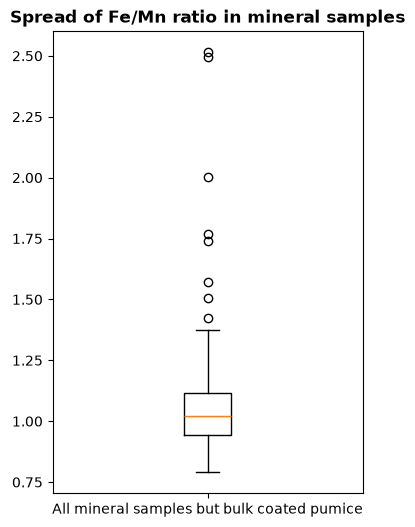

In [330]:
#plot everything except coated pumice
geochem_no_pum = geochem[geochem['Sample_Type'] != 'bulk coated pumice']
fig, ax = plt.subplots(figsize = (4,6))
plt.boxplot(geochem_no_pum['Fe_Mn_ratio'], tick_labels = ["All mineral samples but bulk coated pumice"])  #showfliers= False 
plt.title("Spread of Fe/Mn ratio in mineral samples", weight = "bold")

geochem_no_pum['Fe_Mn_ratio'].mean()
#plt.savefig("Spread of FeMn ratio in mineral samples minus pumice")

In [49]:
#Create geochem_nod with only bulk (surface) nodules
geochem_nod = geochem[geochem['Sample_Type'] == 'bulk nodule']
geochem_nod.head()
#!!geochem_nod ONLY has nodules !!

,Sample_ID,Boxcore,Sample_Type,Min_Dimension,Max_Dimension,Latitude,Longitude,Location_Source,Water_Depth,Fe,...,Gd_Method,Tb_Method,Dy_Method,Y_Method,Ho_Method,Er_Method,Tm_Method,Yb_Method,Lu_Method,Fe_Mn_ratio
0,2026-604-FA-BX03_rep1,BX03,bulk nodule,2.5,2.5,-13.46984,-166.54275,ship,5644.0,158370,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.122555
1,2026-604-FA-BX03_rep2,BX03,bulk nodule,3.0,3.0,-13.46984,-166.54275,ship,5644.0,165300,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.087858
2,2026-604-FA-BX03_rep2_dup,BX03,bulk nodule,3.0,3.0,-13.46984,-166.54275,ship,5644.0,161970,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.088947
3,2026-604-FA-BX03_rep3,BX03,bulk nodule,2.0,2.0,-13.46984,-166.54275,ship,5644.0,174320,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.093738
4,2026-604-FA-BX03_rep4,BX03,bulk nodule,2.5,2.5,-13.46984,-166.54275,ship,5644.0,177410,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.069379


Text(0.5, 1.0, 'Spread of Fe/Mn ratio in mineral samples')

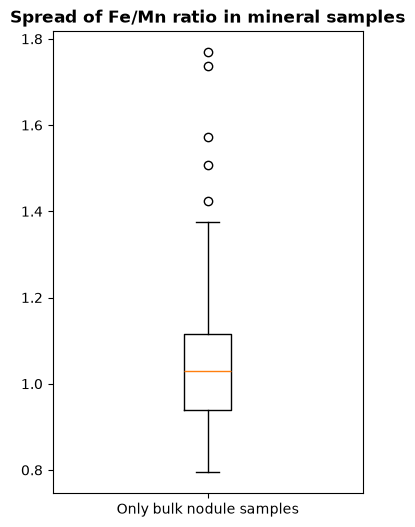

In [333]:
#plt.boxplot(geochem['Fe'])
#plt.boxplot(geochem['Mn'])
fig, ax = plt.subplots(figsize = (4,6))
plt.boxplot(geochem_nod['Fe_Mn_ratio'], tick_labels = ["Only bulk nodule samples"] )  #showfliers= False 
plt.title("Spread of Fe/Mn ratio in mineral samples", weight = "bold")

Text(0.5, 1.0, 'Spread of Fe/Mn ratio in mineral samples')

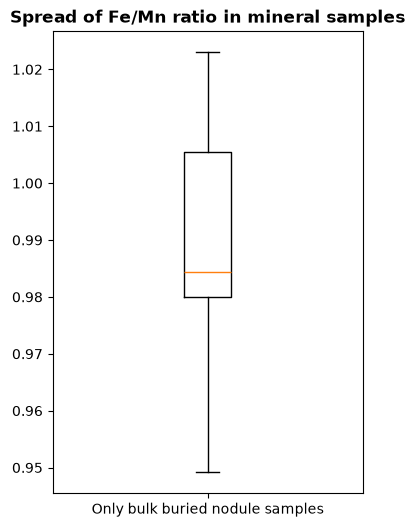

In [334]:
#Look at spread of only buried nodule samples 
fig, ax = plt.subplots(figsize = (4,6))
geochem_nod_buried = geochem[geochem['Sample_Type'] == 'bulk buried nodule']
#geochem_nod_buried
plt.boxplot(geochem_nod_buried['Fe_Mn_ratio'],tick_labels = ["Only bulk buried nodule samples"])  #showfliers= False 
plt.title("Spread of Fe/Mn ratio in mineral samples", weight = "bold")

In [337]:
#Compare oxygen and geochem to each other: geochem_data_cleaned has surface oxygen values and Fe/Mn column added
oxygen_data = pd.read_csv("Geochem_data_cleaned.csv", na_values = -9999)
#Remove pumice and sediment samples so only looking at bulk nod/ buried nod samples:
oxygen_data = oxygen_data[oxygen_data['Sample_Type'] != 'bulk coated pumice']
oxygen_data = oxygen_data[oxygen_data['Sample_Type'] != 'bulk coated sediment']
oxygen_data.head()

,Unnamed: 0,Sample_ID,Boxcore,Surf_oxy,Sample_Type,Min_Dimension,Max_Dimension,Latitude,Longitude,Location_Source,...,Gd_Method,Tb_Method,Dy_Method,Y_Method,Ho_Method,Er_Method,Tm_Method,Yb_Method,Lu_Method,Fe_Mn_ratio
0,0,2026-604-FA-BX03_rep1,BX03,303.711609,bulk nodule,2.5,2.5,-13.46984,-166.54275,ship,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.122555
1,1,2026-604-FA-BX03_rep2,BX03,303.711609,bulk nodule,3.0,3.0,-13.46984,-166.54275,ship,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.087858
2,2,2026-604-FA-BX03_rep2_dup,BX03,303.711609,bulk nodule,3.0,3.0,-13.46984,-166.54275,ship,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.088947
3,3,2026-604-FA-BX03_rep3,BX03,303.711609,bulk nodule,2.0,2.0,-13.46984,-166.54275,ship,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.093738
4,4,2026-604-FA-BX03_rep4,BX03,303.711609,bulk nodule,2.5,2.5,-13.46984,-166.54275,ship,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.069379


np.float64(-0.1600039595518354)

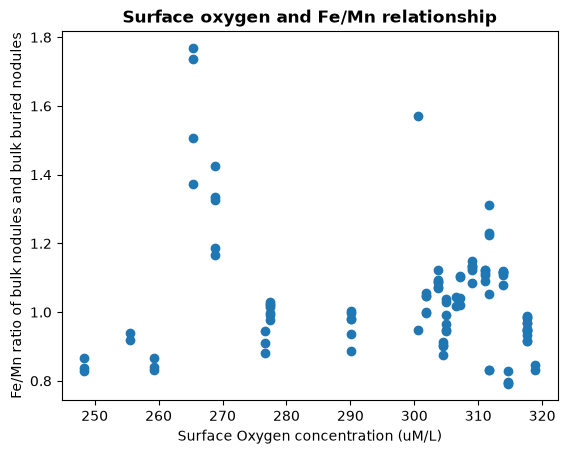

In [339]:
#Plot surf oxy and fe/mn ratio for bulk nod and buried nod samples 
fig, ax = plt.subplots()
ax.scatter(oxygen_data['Surf_oxy'], oxygen_data['Fe_Mn_ratio'])

ax.set_xlabel('Surface Oxygen concentration (uM/L)')
ax.set_ylabel("Fe/Mn ratio of bulk nodules and bulk buried nodules")
ax.set_title("Surface oxygen and Fe/Mn relationship", weight = "bold")

oxygen_data['Surf_oxy'].corr(oxygen_data['Fe_Mn_ratio'])

In [352]:
#Graph endmemeber geochemical data graphs: 
#endmembers only nods datafile has ONLY sample name and element conc in it; pumice and sediment samples removed
#second to last row is the hydrogenetic endmember; last row is diagenetic 
end = pd.read_csv("Endmemebers_onlynod.csv", na_values = -9999)

#Transpose df and make sample ID the column headers 
end = end.set_index('Sample_ID')
end = end.transpose()
end.tail()

Sample_ID,2026-604-FA-BX03_rep1,2026-604-FA-BX03_rep2,2026-604-FA-BX03_rep2_dup,2026-604-FA-BX03_rep3,2026-604-FA-BX03_rep4,2026-604-FA-BX03_rep5,2026-604-FA-BX04_rep1,2026-604-FA-BX04_rep2,2026-604-FA-BX05_rep1,2026-604-FA-BX05_rep2,...,2026-604-FA-BX34_rep6,2026-604-FA-BX34_rep7,2026-604-FA-BX36_rep1,2026-604-FA-BX36_rep2,2026-604-FA-BX36_rep3,2026-604-FA-BX36_rep4,2026-604-FA-BX36_rep5,2026-604-FA-BX36_rep6,West pacific Nodule Field (hydro),Peru basin (Dia)
Er,22.30,21.9,21.40,22.40,21.40,23.20,18.90,17.30,19.20,15.60,...,23.00,23.20,24.00,22.90,22.10,22.80,21.70,17.40,24.0,9.8
Tm,3.13,3.1,3.07,3.19,3.04,3.29,2.67,2.42,2.69,2.20,...,3.33,3.41,3.41,3.39,3.22,3.34,3.12,2.50,3.8,1.5
Yb,20.90,20.3,21.00,21.10,20.30,21.80,17.60,16.10,17.80,14.40,...,22.50,22.70,22.90,22.40,21.20,22.20,21.00,17.10,25.0,10.3
Lu,3.33,3.3,3.32,3.37,3.21,3.54,2.81,2.58,2.73,2.28,...,3.59,3.60,3.63,3.61,3.41,3.60,3.38,2.81,3.9,1.6
Ce,1017.00,1110.0,1063.00,1092.00,1022.00,1061.00,569.00,412.00,963.00,817.00,...,1146.00,1069.00,1163.00,1111.00,1100.00,1146.00,1144.00,1081.00,1497.0,110.0


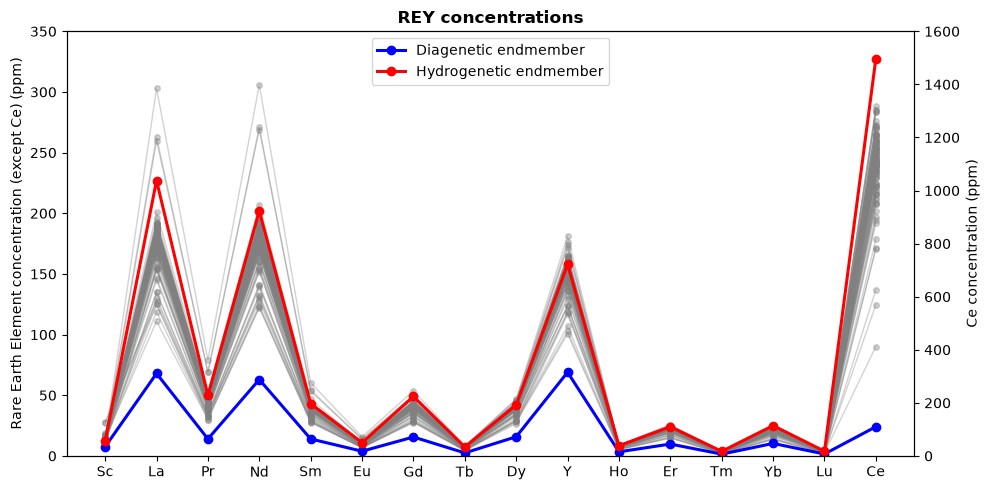

In [351]:
#plot REY for samples and endmembers

#Copy entire thing:
end_scaled = end.copy()

# Y values for all the samples except Ce
y1_min, y1_max = 0, 350  
#Ce needed scale:
y2_min, y2_max = 0, 1600
# Put Ce to main scale but used sized up values (Ce in last row of df)
ce_row = end_scaled.iloc[-1]
end_scaled.iloc[-1] = (ce_row - y2_min) / (y2_max - y2_min) * (y1_max - y1_min) + y1_min



fig, ax = plt.subplots(figsize=(10, 5))

#all samples
ax.plot(end_scaled.iloc[-16:, :-2], color="gray", alpha=0.35,linewidth=1, marker="o", markersize=4,)

#Diagenetic endmember
ax.plot( end_scaled.iloc[-16:, -1:],  color="blue", alpha=1.0, linewidth=2.2, marker="o", markersize=6, label="Diagenetic endmember",)

#Hydrogenetic endmember
ax.plot(end_scaled.iloc[-16:, -2:-1], color="red", alpha=1.0, linewidth=2.2, marker="o", markersize=6, label="Hydrogenetic endmember",)

#Left axis: all samples but Ce
ax.set_ylim(y1_min, y1_max)
ax.set_ylabel("Rare Earth Element concentration (except Ce) (ppm)")

#Right acis: just Ce
ax2 = ax.twinx()
ax2.set_ylim(y2_min, y2_max)
ax2.set_ylabel("Ce concentration (ppm)")

ax.legend()
ax.set_title("REY concentrations", weight = 'bold')
plt.tight_layout()

fig.savefig("REY element concentration.png", dpi = 300, bbox_inches = 'tight')
plt.show()

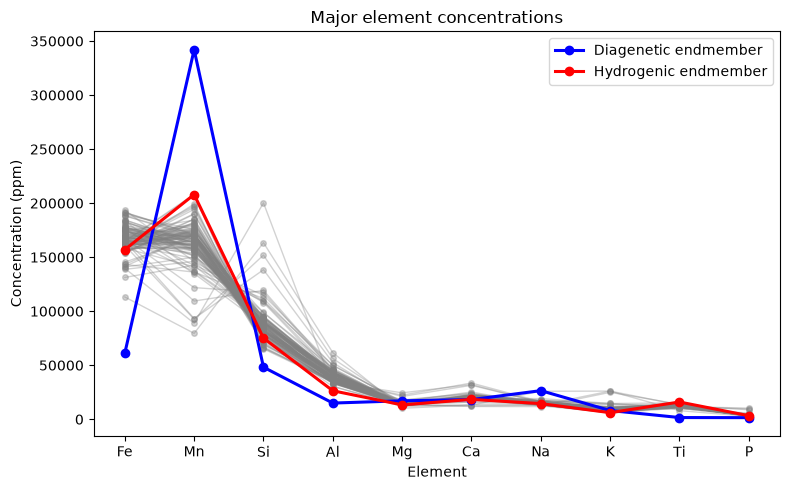

In [301]:
#Plot major elements 
fig, ax = plt.subplots(figsize=(8, 5))

#all samples
ax.plot(end.iloc[:10, :-2], color='gray', alpha=0.35, linewidth=1, marker='o',  markersize=4)

#diagenetic
ax.plot(end.iloc[:10, -1:], color='blue', alpha=1.0, linewidth=2.2, marker='o', markersize=6, label = "Diagenetic endmember")

#hydrogenetic
ax.plot(end.iloc[:10, -2:-1], color='red', alpha=1.0, linewidth=2.2, marker='o', markersize=6, label = "Hydrogenic endmember")

ax.set_xlabel('Element')
ax.set_ylabel('Concentration (ppm)')
ax.set_title('Major element concentrations')
ax.legend()
plt.tight_layout()
plt.show()
fig.savefig("Major element concentration.png", dpi = 300, bbox_inches = 'tight')

In [139]:
#Create new column in gochem_nod df (only buried and surface nods) for ternary plot calculation
geochem_nod['Ni+Co+Cu_times10'] = (geochem_nod['Ni'] + geochem_nod['Co'] +geochem_nod['Cu'])*10
geochem_nod.head()

C:\Users\isabe\AppData\Local\Temp\ipykernel_41936\412920137.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  geochem_nod['Ni+Co+Cu_times10'] = (geochem_nod['Ni'] + geochem_nod['Co'] +geochem_nod['Cu'])*10


,Sample_ID,Boxcore,Sample_Type,Min_Dimension,Max_Dimension,Latitude,Longitude,Location_Source,Water_Depth,Fe,...,Tb_Method,Dy_Method,Y_Method,Ho_Method,Er_Method,Tm_Method,Yb_Method,Lu_Method,Fe_Mn_ratio,Ni+Co+Cu_times10
0,2026-604-FA-BX03_rep1,BX03,bulk nodule,2.5,2.5,-13.46984,-166.54275,ship,5644.0,158370,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.122555,75520
1,2026-604-FA-BX03_rep2,BX03,bulk nodule,3.0,3.0,-13.46984,-166.54275,ship,5644.0,165300,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.087858,84110
2,2026-604-FA-BX03_rep2_dup,BX03,bulk nodule,3.0,3.0,-13.46984,-166.54275,ship,5644.0,161970,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.088947,79520
3,2026-604-FA-BX03_rep3,BX03,bulk nodule,2.0,2.0,-13.46984,-166.54275,ship,5644.0,174320,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.093738,81880
4,2026-604-FA-BX03_rep4,BX03,bulk nodule,2.5,2.5,-13.46984,-166.54275,ship,5644.0,177410,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.069379,81410


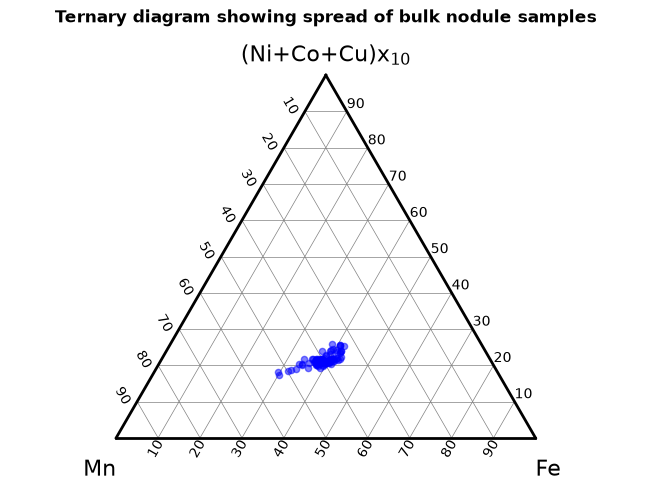

In [154]:
#make ternary plot: 
import matplotlib.pyplot as plt
from ternary_diagram import TernaryDiagram
fig, ax = plt.subplots(layout="constrained")


td = TernaryDiagram(["(Ni+Co+Cu)x10", "Mn", "Fe"], ax=ax)
td.scatter(geochem_nod[["Ni+Co+Cu_times10", "Fe", "Mn"]], marker="o", c="blue", s=20, alpha = .5)

ax.set_title("Ternary diagram showing spread of bulk nodule samples", weight = "bold", pad = 25)
fig.savefig("tern diagram.png", dpi = 300, bbox_inches = 'tight')

In [51]:
geochem_nod.head()

,Sample_ID,Boxcore,Sample_Type,Min_Dimension,Max_Dimension,Latitude,Longitude,Location_Source,Water_Depth,Fe,...,Gd_Method,Tb_Method,Dy_Method,Y_Method,Ho_Method,Er_Method,Tm_Method,Yb_Method,Lu_Method,Fe_Mn_ratio
0,2026-604-FA-BX03_rep1,BX03,bulk nodule,2.5,2.5,-13.46984,-166.54275,ship,5644.0,158370,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.122555
1,2026-604-FA-BX03_rep2,BX03,bulk nodule,3.0,3.0,-13.46984,-166.54275,ship,5644.0,165300,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.087858
2,2026-604-FA-BX03_rep2_dup,BX03,bulk nodule,3.0,3.0,-13.46984,-166.54275,ship,5644.0,161970,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.088947
3,2026-604-FA-BX03_rep3,BX03,bulk nodule,2.0,2.0,-13.46984,-166.54275,ship,5644.0,174320,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.093738
4,2026-604-FA-BX03_rep4,BX03,bulk nodule,2.5,2.5,-13.46984,-166.54275,ship,5644.0,177410,...,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,ICP_MS_FUS,1.069379


In [ ]:
#PCA based on datacamp example: still need to work this one out...

In [353]:
#geochem_boxcore_variability

#avgs=geochem_nod.groupby("Boxcore").agg(['mean', 'std'], numeric_only = True)

num_cols = geochem_nod.select_dtypes(include="number").columns.tolist()

# 2. Ensure 'Boxcore' is included if it isn't already numeric
if "Boxcore" not in num_cols:
  num_cols.append("Boxcore")

# 3. Group and aggregate
avgs = geochem_nod[num_cols].groupby("Boxcore").agg(["mean", "std"])

#avgs.to_csv("averages.csv")

In [354]:
avgs=avgs.iloc[:,10:142]
avgs.transpose()
avgs.head()

Fe                          Mn                \
                  mean          std           mean           std   
Boxcore                                                            
BX03     169478.333333  8763.737597  155703.333333  10250.772979   
BX04     136090.000000  6858.935778  146320.000000   5161.879503   
BX05     164575.000000  2683.759800  104272.500000  14065.585365   
BX06     143376.666667  2016.093582  169956.666667   1755.714479   
BX07     164230.000000  4374.991429  159608.000000   5072.466855   

                    Si                          Al                         Mg  \
                  mean           std          mean          std          mean   
Boxcore                                                                         
BX03      92355.000000  11286.933596  38640.000000  4357.985773  12908.333333   
BX04     112070.000000   3917.371568  49900.000000    70.710678  16145.000000   
BX05     131765.000000  16435.462675  49825.000000  5484.295762  13955.000000   
BX06      94803.333333   3482.159292  43553.333333  3337.309295  13673.333333   
BX07      91652.000000   5019.314694  40560.000000  3166.346475  13564.000000   

                      ...        Ho                   Er                  Tm  \
                 std  ...      mean       std       mean       std      mean   
Boxcore               ...                                                      
BX03      630.219538  ...  7.623333  0.235938  22.100000  0.687023  3.136667   
BX04      445.477272  ...  6.285000  0.431335  18.100000  1.131371  2.545000   
BX05     1245.806298  ...  6.327500  1.101374  17.900000  3.123033  2.480000   
BX06      240.901086  ...  6.413333  0.513939  18.966667  1.537314  2.690000   
BX07      324.853813  ...  8.158000  0.562734  23.540000  1.887591  3.306000   

                          Yb                Lu            
              std       mean       std    mean       std  
Boxcore                                                   
BX03     0.091141  20.900000  0.562139  3.3450  0.109316  
BX04     0.176777  16.850000  1.060660  2.6950  0.162635  
BX05     0.381663  16.300000  2.546894  2.5575  0.372592  
BX06     0.216564  18.333333  1.588500  3.0100  0.234307  
BX07     0.236284  22.140000  1.484251  3.5760  0.264632  

[5 rows x 132 columns]

In [355]:
sed = pd.read_csv("Table1_raw_XRF_data (1).csv", na_values = -9999)
sed.head()

,ID,Na,Mg,Al,Si,P,S,Cl,K,Ca,...,Br,Rb,Sr,Y,Zr,Nb,Mo,Ba,Pb,Th
0,Sed,20423,17725,42274,158979,1374,2470,32098,15329,21556,...,251,93,339,54,170,20,NaN,254,51,NaN
1,Sed,27645,14674,31639,125254,1080,2212,40597,13087,19728,...,226,84,311,54,160,19,NaN,203,55,NaN
2,Sed,20136,17242,41646,155543,1424,2561,32813,15315,20160,...,259,95,353,55,190,22,8.0,314,101,16.0
3,Sed,22244,16366,38120,145741,1242,2312,34185,14548,20230,...,264,94,317,53,160,18,NaN,199,50,NaN
4,Sed,19423,16593,45560,169758,1170,2548,30165,17685,17315,...,268,111,301,51,156,17,NaN,259,65,14.0


In [356]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [357]:
Nod_NoID = pd.read_csv("Nod_geochem.csv", na_values = [-9999, -8888])
Nod_NoID.head()
Nod_NoID = Nod_NoID.rename(columns = {"Unnamed: 0": "ID"})

Nod_NoID.head()

,ID,Fe,Mn,Si,Al,Mg,Ca,Na,K,Ti,...,Eu,Gd,Tb,Dy,Y,Ho,Er,Tm,Yb,Lu
0,nod,158370,141080,109020,43940,12270,18430,15740,10840,14030,...,9.16,38.7,6.28,38.3,152.3,7.73,22.3,3.13,20.9,3.33
1,nod,165300,151950,95740,40830,12600,19680,15340,10480,14610,...,9.18,37.5,6.32,38.1,146.9,7.51,21.9,3.10,20.3,3.30
2,nod,161970,148740,94420,42540,12620,19150,16330,10130,14300,...,9.04,38.3,6.31,38.0,142.7,7.35,21.4,3.07,21.0,3.32
3,nod,174320,159380,85490,36170,13100,20210,14660,9240,15510,...,9.30,38.4,6.29,38.3,149.6,7.68,22.4,3.19,21.1,3.37
4,nod,177410,165900,94220,34880,12790,20390,16050,10710,15270,...,8.89,36.7,6.14,37.5,143.2,7.46,21.4,3.04,20.3,3.21


In [358]:
sed_NoID = pd.read_csv("Table1_raw_XRF_data (1).csv", na_values = -9999)

sed_NoID.head()

,ID,Na,Mg,Al,Si,P,S,Cl,K,Ca,...,Br,Rb,Sr,Y,Zr,Nb,Mo,Ba,Pb,Th
0,Sed,20423,17725,42274,158979,1374,2470,32098,15329,21556,...,251,93,339,54,170,20,NaN,254,51,NaN
1,Sed,27645,14674,31639,125254,1080,2212,40597,13087,19728,...,226,84,311,54,160,19,NaN,203,55,NaN
2,Sed,20136,17242,41646,155543,1424,2561,32813,15315,20160,...,259,95,353,55,190,22,8.0,314,101,16.0
3,Sed,22244,16366,38120,145741,1242,2312,34185,14548,20230,...,264,94,317,53,160,18,NaN,199,50,NaN
4,Sed,19423,16593,45560,169758,1170,2548,30165,17685,17315,...,268,111,301,51,156,17,NaN,259,65,14.0


In [359]:
NoID = pd.concat([sed_NoID,Nod_NoID], ignore_index = True)
NoID = NoID.dropna(axis = 1)

In [360]:
NoID.head()

,ID,Na,Mg,Al,Si,P,S,K,Ca,Ti,...,Zn,Ga,As,Rb,Sr,Y,Zr,Nb,Ba,Pb
0,Sed,20423,17725,42274,158979,1374,2470,15329,21556,11087,...,187,17.0,39.0,93.0,339,54.0,170,20.0,254,51.0
1,Sed,27645,14674,31639,125254,1080,2212,13087,19728,10179,...,174,15.0,37.0,84.0,311,54.0,160,19.0,203,55.0
2,Sed,20136,17242,41646,155543,1424,2561,15315,20160,11169,...,204,19.0,52.0,95.0,353,55.0,190,22.0,314,101.0
3,Sed,22244,16366,38120,145741,1242,2312,14548,20230,9997,...,178,14.0,37.0,94.0,317,53.0,160,18.0,199,50.0
4,Sed,19423,16593,45560,169758,1170,2548,17685,17315,8368,...,182,17.0,38.0,111.0,301,51.0,156,17.0,259,65.0


In [361]:
features = NoID.columns.to_numpy()
features = np.delete(features, 0)
features

array(['Na', 'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'V', 'Cr', 'Mn',
       'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'As', 'Rb', 'Sr', 'Y', 'Zr',
       'Nb', 'Ba', 'Pb'], dtype=object)

In [362]:
x = NoID.loc[:, features].values
x = StandardScaler().fit_transform(x) # normalizing the features

In [363]:
np.mean(x),np.std(x)
feat_cols = ['feature'+str(i) for i in range(x.shape[1])]
normalised_geo = pd.DataFrame(x,columns=feat_cols)


In [364]:
pca_geo = PCA(n_components=2)
principalComponents_geo = pca_geo.fit_transform(x)

In [365]:
principal_geo_Df = pd.DataFrame(data = principalComponents_geo, columns = ['principal component 1', 'principal component 2'])

In [366]:
print('Explained variability per principal component: {}'.format(pca_geo.explained_variance_ratio_))

##amount of variance each principal component holds after projecting the data into a lower dimensional subspace:


#principal component 1 holds 74% of the information, while principal component 2 holds 11% 



Explained variability per principal component: [0.7545878  0.11058243]


<Figure size 640x480 with 0 Axes>

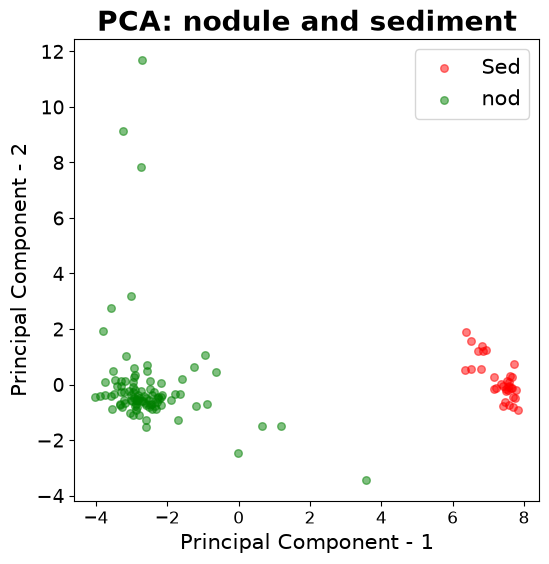

In [367]:
plt.figure()
plt.figure(figsize=(6,6))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Principal Component - 1',fontsize=15)
plt.ylabel('Principal Component - 2',fontsize=15)
plt.title("PCA: nodule and sediment",fontsize=20, weight = "bold")


targets = ['Sed', 'nod']
colors = ['r', 'g']
for target, color in zip(targets,colors):
    indicesToKeep = NoID['ID'] == target
    plt.scatter(principal_geo_Df.loc[indicesToKeep, 'principal component 1']
               , principal_geo_Df.loc[indicesToKeep, 'principal component 2'], c = color, s = 30, alpha = 0.5)

plt.legend(targets,prop={'size': 15})

In [ ]:
# very linearly separated.
#nod more spread out compared to sed 

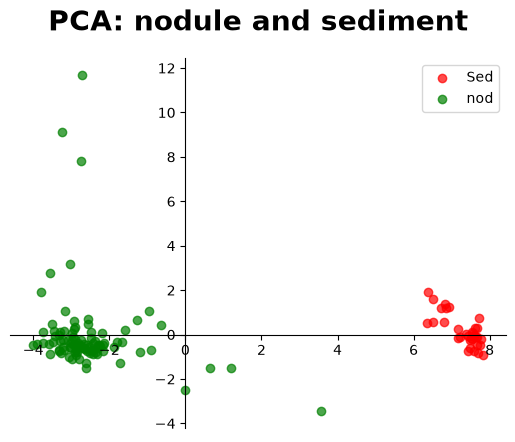

In [368]:

fig, ax = plt.subplots()

#plt.xticks(fontsize=12)
#plt.yticks(fontsize=14)
#plt.xlabel('Principal Component - 1',fontsize=15)
#plt.ylabel('Principal Component - 2',fontsize=15)
ax.set_title("PCA: nodule and sediment",fontsize=20, weight = "bold", pad = 20)


targets = ['Sed', 'nod']
colors = ['r', 'g']
for target, color in zip(targets,colors):
    indicesToKeep = NoID['ID'] == target
    ax.scatter(principal_geo_Df.loc[indicesToKeep, 'principal component 1'], principal_geo_Df.loc[indicesToKeep, 'principal component 2'], c = color, alpha = 0.7, label = ["ID"])



# set the x-spine
ax.spines['left'].set_position('zero')

# turn off the right spine/ticks
ax.spines['right'].set_color('none')
ax.yaxis.tick_left()

# set the y-spine
ax.spines['bottom'].set_position('zero')

# turn off the top spine/ticks
ax.spines['top'].set_color('none')
ax.xaxis.tick_bottom()


ax.legend(targets)